# Gaussian Process Regression

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%config InlineBackend.figure_format = 'png'

# Fix the random seed so results are reproducible.
np.random.seed(42)

In [3]:
plt.style.use('ggplot')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['lines.linewidth'] = 2

colors = ['#008fd5', '#fc4f30', '#e5ae38', '#6d904f', '#8b8b8b', '#810f7c', '#137e6d', '#be0119', '#3b638c', '#af6f09','#c79fef', '#80f9ad']

Consider the (hidden) function 
$$f(x)=\sin\left(\frac{3\pi x}{10}\right)+\cos\left(\frac{7\pi x}{10}\right)$$

In [583]:
d = 1

def f(x):
    f = np.sin((3*np.pi)*x/10) + np.cos((7*np.pi)*x/10)
    return(f)

In [584]:
xx = np.linspace(start=0, stop=10, num=1000)
yy = f(xx)

## Generate Data Samples

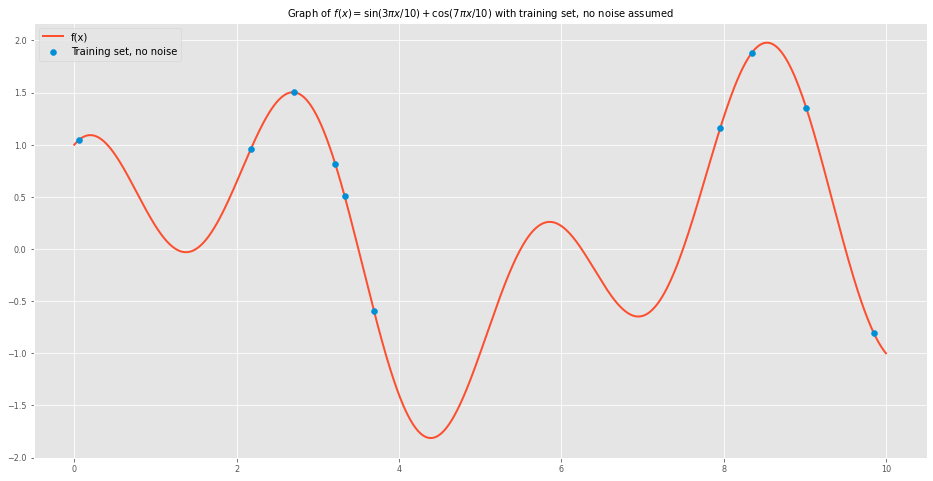

In [585]:
# Number of samples (training set). 
n = 10
x = np.random.rand(n)*10
x = np.sort(x)
t = f(x)

fig, ax = plt.subplots()
plt.plot(xx, yy, color=colors[1], label='f(x)', zorder=2)
plt.scatter(x, t, color=colors[0], label='Training set, no noise', zorder=3)

plt.legend(loc='upper left')
plt.title(r'Graph of $f(x) = \sin(3\pi x/10) + \cos(7\pi x/10)$ with training set, no noise assumed');

Next, we generate some training sample observations for the case when a gaussian noise is assumed:

In [586]:
# Error standard deviation. 
sigma_n = 0.2

# Errors.
epsilon = np.random.normal(loc=0, scale=sigma_n, size=n)

# Observed target variable. 
t_n = t + epsilon

Let us see the error distribution.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
# Plot errors (sns.distplot is deprecated/removed: use histplot with KDE).
sns.histplot(x=epsilon, kde=True, stat='density', color=colors[1], ax=ax)
ax.set(title='Errors Distribution');

Let us now visualize the sample data:

In [ ]:
fig, ax = plt.subplots()
plt.plot(xx, yy, color=colors[1], label='f(x)', zorder=2)
plt.scatter(x, t_n, color=colors[0], label='Training set, gaussian noise', zorder=3)

plt.legend(loc='upper left')
plt.title(r'Graph of $f(x) = \sin(3\pi x/10) + \cos(7\pi x/10)$ with training set, gaussian noise assumed, $\sigma_n={}$'.format(sigma_n));

We now consider test data points on which we want to generate predictions.

In [520]:
#n_star = 1000
#x_star = np.sort(np.random.rand(n_star))
x_star = xx

## Kernel Function

A gaussian process is completely specified by its mean and covariance functions $m(x), \kappa(x,x')$. Usually, it is assumed $m(x)=0$, while a common choice for $\kappa(x,x')$ is the *squared exponential*, 

$$
\text{cov}(f(x_p), f(x_q)) = \kappa_{\sigma_f, \ell}(x_p, x_q) = \sigma_f \exp\left(-\frac{\lVert x_p - x_q\rVert^2}{2\ell^2} \right)
$$

where $\sigma_f , \ell >0$ are hyperparameters.

In [ ]:
def kernel_function(x, y, sigma_f=1, l=1):
    """Squared exponential kernel, vectorized: returns the matrix kappa(x_i, y_j)."""
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)
    return sigma_f*np.exp(-((x - y)**2)/(2*l**2))


def is_positive_definite(A):
    """Check positive definiteness via Cholesky (np.linalg.det under/overflows on large matrices)."""
    try:
        np.linalg.cholesky(A)
        return True
    except np.linalg.LinAlgError:
        return False


def sample_mvn(mean, cov, size=None, jitter=1e-8):
    """Sample from N(mean, cov), adding a small jitter to the diagonal for numerical stability."""
    cov = (cov + cov.T)/2 + jitter*np.eye(cov.shape[0])
    return np.random.multivariate_normal(mean=mean, cov=cov, size=size)

Let us select the parameters:

In [522]:
l = .8
sigma_f = 1

## Compute Covariance Matrices

Let us denote by $K(X, X) \in M_{n}(\mathbb{R})$, $K(X_*, X) \in M_{n_* \times n}(\mathbb{R})$ and $K(X_*, X_*) \in M_{n_*}(\mathbb{R})$ the covariance matrices applies to $x$ and  $x_*$. 

In [ ]:
def compute_cov_matrices(x, x_star, sigma_f=1, l=1, noise=True, sigma_n=0.1):
    """
    Compute components of the covariance matrix of the joint distribution.
    
    We follow the notation:
    
        - K = K(X) 
        - k_star = k(X_*, X)
        - K_star = K(X_*)
    """
    n = x.shape[0]

    K = kernel_function(x, x, sigma_f=sigma_f, l=l)
    K_star = kernel_function(x_star, x_star, sigma_f=sigma_f, l=l)
    k_star = kernel_function(x_star, x, sigma_f=sigma_f, l=l)

    if noise:
        K = K+(sigma_n**2)*np.eye(n)
    
    a = np.concatenate((K, k_star), axis=0)
    b = np.concatenate((k_star.T, K_star), axis=0)
    C = np.concatenate((a, b), axis=1)
    
    return (C, K, K_star, k_star)

## No noise assumption

We assume the observed values $t=(t_1,\ldots,t_n)^T$ in correspondance to the training set items $X=(x_1,\ldots,x_n)^T$ are precisely the values $$f=(f(x_1),\ldots,f(x_n))^T$$ 

In this case, given the set of test points $X^*=(x^*_1,\ldots,x^*_m)^T$ the joint distribution of $f$ and $f^*=(f(x_1^*),\ldots,f(x_m^*))^T$ is given by 

$$
\left(
\begin{array}{c}
f \\
f_*
\end{array}
\right)
\sim
\mathcal{N}(0, C)
$$

where 

$$
C = 
\left(
\begin{array}{cc}
K(X) & k(X, X^*) \\
k(X, X^*)^T & K(X^*)
\end{array}
\right)
$$
and

- $K(X)_{ij} = \kappa(x_i,x_j)$, with $i,j =1,\ldots, n$ 
- $k(X,X^*)_{ij} = \kappa(x_i,x^*_j)$, with $i=1,\ldots, n$  and $j=1,\ldots, m$
- $K(X^*)_{ij} = \kappa(x^*_i,x^*_j)$, with $i,j =1,\ldots, m$ 

Let us compute the components:

In [524]:
C_n, K_n, K_star_n, k_star = compute_cov_matrices(x, x_star, sigma_f=sigma_f, l=l, noise=False)

Let us consider each component:

$K(X)$

In [525]:
print('Shape: {}'.format(K_n.shape))

Shape: (10, 10)


In [ ]:
print('Positive definite: {}'.format(is_positive_definite(K_n)))

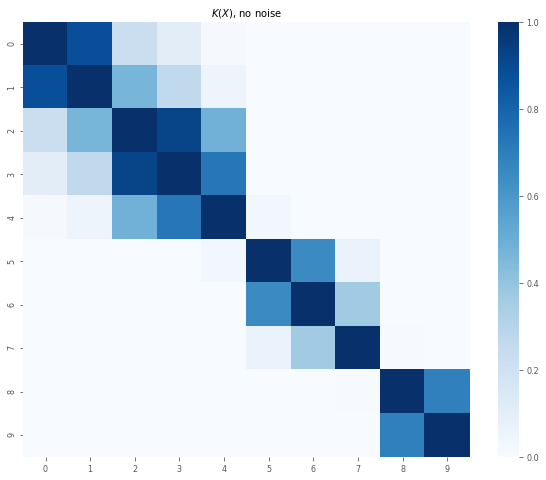

In [527]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=K_n, cmap='Blues', ax=ax)
plt.title('$K(X)$, no noise');

$K(X_*)$

In [528]:
print('Shape: {}'.format(K_star_n.shape))

Shape: (1000, 1000)


In [ ]:
# K(X_*) is positive semi-definite but numerically singular (1000 very close points):
# its smallest eigenvalue is ~0 (up to rounding), so Cholesky may fail.
print('Positive definite: {}'.format(is_positive_definite(K_star_n)))
print('Min eigenvalue: {:.2e}'.format(np.linalg.eigvalsh(K_star_n).min()))

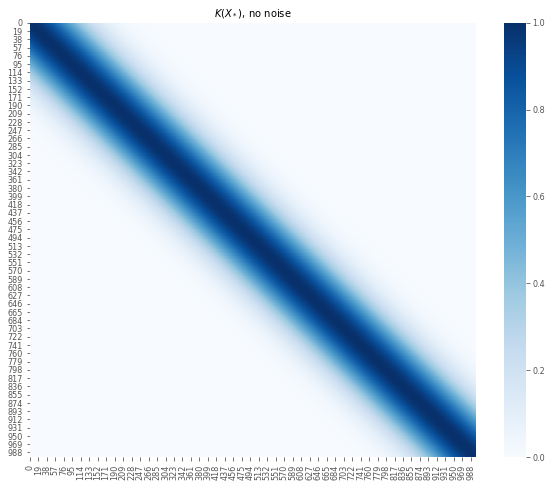

In [530]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=K_star_n, cmap='Blues', ax=ax)
plt.title('$K(X_*)$, no noise');

$k(X_*,X)$

In [531]:
print('Shape: {}'.format(k_star.shape))

Shape: (1000, 10)


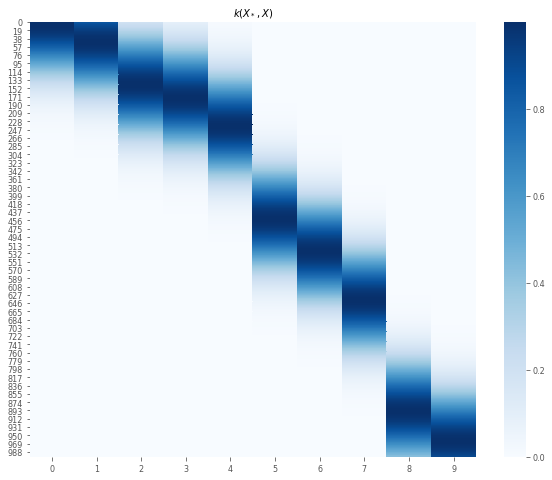

In [532]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=k_star, cmap='Blues', ax=ax)
plt.title('$k(X_*,X)$');

The covariance matrix $C_n$

In [533]:
print('Shape: {}'.format(C_n.shape))

Shape: (1010, 1010)


In [ ]:
print('Positive definite: {}'.format(is_positive_definite(C_n)))
print('Min eigenvalue: {:.2e}'.format(np.linalg.eigvalsh(C_n).min()))

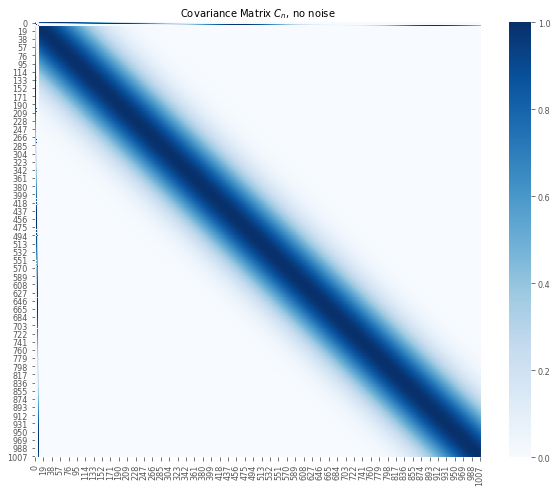

In [535]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=C_n, cmap='Blues', ax=ax)
plt.title('Covariance Matrix $C_n$, no noise');

The prior distribution for $f^*$ is $N(\mu, \Sigma)$, with $\mu=0$ and $\Sigma=K(X^*)$

In [ ]:
fig, ax = plt.subplots()
mean_z = np.zeros_like(xx)
for i in range(0, 20):
    # Sample from prior distribution. 
    z_star = sample_mvn(mean=mean_z, cov=K_star_n)
    # Plot function.
    plt.plot(xx, z_star, color=colors[0], alpha=0.3)
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='Samples of Prior Distribution, no noise')
ax.legend(loc='lower right');

In [ ]:
def compute_gpr_parameters(K, K_star, k_star, y):
    """Compute gaussian regression parameters."""
    n = K.shape[0]
    # Solve linear systems instead of inverting K (more stable and faster).
    # Mean.
    f_bar_star = np.dot(k_star, np.linalg.solve(K, y.reshape([n, d])))
    # Covariance.
    cov_f_star = K_star - np.dot(k_star, np.linalg.solve(K, k_star.T))
    
    return (f_bar_star, cov_f_star)

In [538]:
m, c = compute_gpr_parameters(K_n, K_star_n, k_star, t)

In [ ]:
fig, ax = plt.subplots()
for i in range(0, 20):
    # Sample from joint distribution. 
    z_star = sample_mvn(mean=m.ravel(), cov=c)
    # Plot function.
    plt.plot(xx, z_star, color=colors[0], alpha=0.3)
plt.scatter(x, t, color=colors[7], zorder=3)
    
# Plot "true" function.
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='Samples of Posterior Distribution, no noise')
ax.legend(loc='lower right');

In [ ]:
def predict(x_new, X_train, t_train, noise=False):
    """Predictive mean and standard deviation at the points x_new (vectorized)."""
    C, K, K_star, k_star = compute_cov_matrices(X_train, np.atleast_1d(x_new), l=l, sigma_n=sigma_n, sigma_f=sigma_f, noise=noise)
    m, c = compute_gpr_parameters(K, K_star, k_star, t_train)
    # Clip tiny negative variances caused by rounding before taking the square root.
    return m.ravel(), np.sqrt(np.clip(np.diag(c), 0, None))

In [ ]:
fig, ax = plt.subplots()
mean_pred, std_pred = predict(xx, x, t)

plt.plot(xx, mean_pred, color=colors[3], label='mean prediction')
plt.fill_between(xx, mean_pred-2*std_pred, mean_pred+2*std_pred, color=colors[3], alpha=.3, label='±2 std')
plt.scatter(x, t, color=colors[4], zorder=3)
    
# Plot "true" function.
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='Predictive Distribution, no noise')
ax.legend(loc='lower right');

## Gaussian noise assumption

The joint distribution  of $y$ and $f_*$ is given by 

$$
\left(
\begin{array}{c}
y \\
f_*
\end{array}
\right)
\sim
N(0, C)
$$

where 

$$
C = 
\left(
\begin{array}{cc}
K(X, X) + \sigma^2_n I & K(X, X_*) \\
K(X_*, X) & K(X_*, X_*)
\end{array}
\right)
$$

Observe that we need to add the term $\sigma^2_n I$ to the upper left component to account for noise (assuming additive independent identically distributed Gaussian noise). We now compute the matrix $C$.

In [ ]:
C_g, K_g, K_star_g, k_star = compute_cov_matrices(x, x_star, sigma_f=sigma_f, sigma_n=sigma_n, l=l, noise=True)

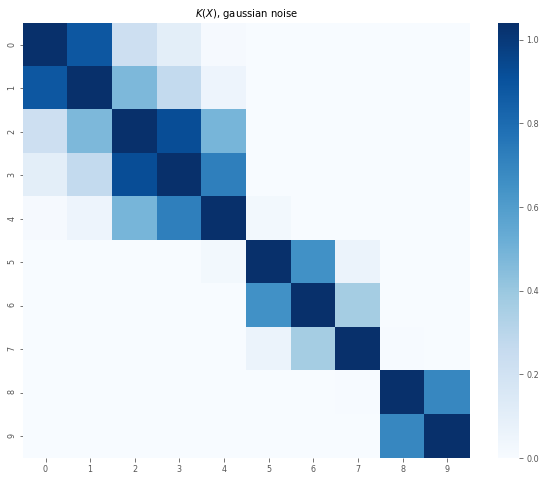

In [544]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=K_g, cmap='Blues', ax=ax)
plt.title('$K(X)$, gaussian noise');

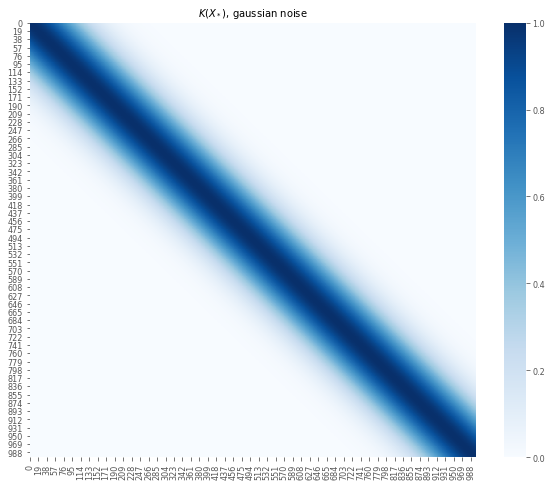

In [545]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=K_star_g, cmap='Blues', ax=ax)
plt.title('$K(X_*)$, gaussian noise');

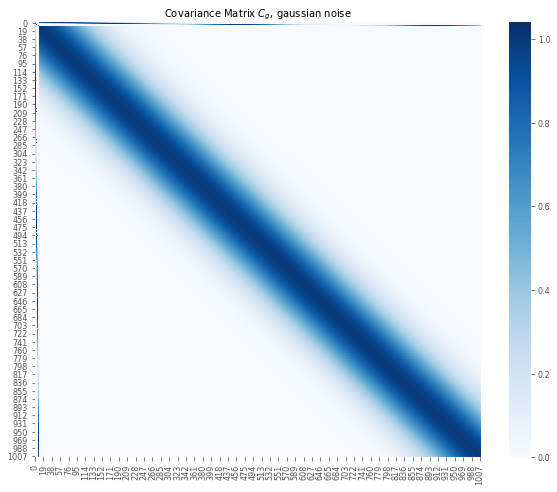

In [546]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=C_g, cmap='Blues', ax=ax)
plt.title('Covariance Matrix $C_g$, gaussian noise');

Let us verify that $C$ is symmetric.

In [547]:
np.all(C_g.T == C_g)

True

Verify C is positive definite

In [ ]:
# The noise term only regularizes K(X); the K(X_*) block stays numerically singular.
print('Positive definite: {}'.format(is_positive_definite(C_g)))
print('Min eigenvalue: {:.2e}'.format(np.linalg.eigvalsh(C_g).min()))

## Prior Distribution 

The prior distribution for $f_*$ is $N(\mu, \Sigma)$, with $\mu=0$ and $\Sigma$ defined by $\kappa(x,x')$. Let us visualize some sample functions from this prior:

In [ ]:
fig, ax = plt.subplots()
mean_z = np.zeros_like(xx)
for i in range(0, 20):
    # Sample from prior distribution. 
    z_star = sample_mvn(mean=mean_z, cov=K_star_g)
    # Plot function.
    plt.plot(xx, z_star, color=colors[0], alpha=0.3)
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='Samples of Prior Distribution, gaussian noise')
ax.legend(loc='lower right');

In [ ]:
# Use the noisy observations t_n (not the noise-free t).
m_g, c_g = compute_gpr_parameters(K_g, K_star_g, k_star, t_n)

In [ ]:
fig, ax = plt.subplots()
for i in range(0, 20):
    # Sample from joint distribution. 
    z_star = sample_mvn(mean=m_g.ravel(), cov=c_g)
    # Plot function.
    plt.plot(xx, z_star, color=colors[0], alpha=0.2)
plt.scatter(x, t_n, color=colors[7], zorder=3)
    
# Plot "true" function.
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='Samples of Posterior Distribution, gaussian noise')
ax.legend(loc='lower right');

In [ ]:
fig, ax = plt.subplots()
mean_pred, std_pred = predict(xx, x, t_n, noise=True)

plt.plot(xx, mean_pred, color=colors[3], label='mean prediction')
plt.fill_between(xx, mean_pred-2*std_pred, mean_pred+2*std_pred, color=colors[3], alpha=.3, label='±2 std')
plt.scatter(x, t_n, color=colors[4], zorder=3)
    
# Plot "true" function.
plt.plot(xx, yy, color=colors[1], label='f(x)')
ax.set(title='Predictive Distribution, gaussian noise')
ax.legend(loc='lower right');

## Hyperparameters

We now study the effect of the hyperparameters $\sigma_f$ and $\ell$ of the kernel function defined above. 

- The hyperparameter $\sigma_f$ describes the amplitude of the function. 

- The hyperparameter $\ell$ is a locality parameter, i.e. how far the points interact. 

Let us see some concrete examples:

- \\(\sigma_f = 2\\) and \\(\ell = 1\\)

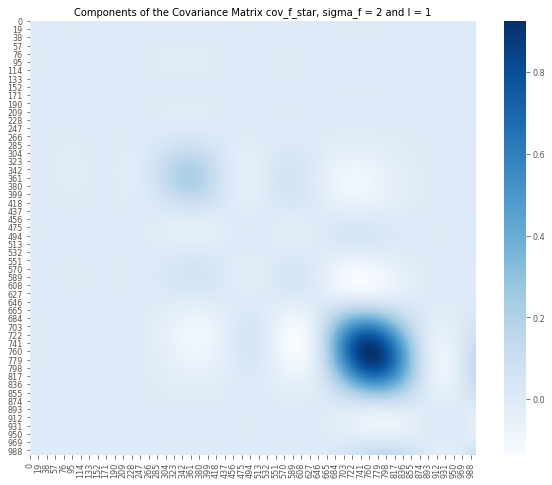

In [554]:
l = 1
sigma_f = 2

# Compute covariance matrices. 
C, K, K_star, k_star = compute_cov_matrices(x, x_star, sigma_f=sigma_f, l=l, noise=False)
# Compute gaussian process parameters. 
f_bar_star, cov_f_star = compute_gpr_parameters(K, K_star, k_star, t)

# Plot posterior covariance matrix components. 
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=cov_f_star, cmap='Blues', ax=ax)
plt.title(f'Components of the Covariance Matrix cov_f_star, sigma_f = {sigma_f} and l = {l}');

In this case the values of the posterior covariance matrix are not that localized. This means that we expect points far away can still have some interaction, i.e. the fit becomes more global. Let us plot the resulting fit:

In [ ]:
C, K, K_star, k_star = compute_cov_matrices(x, x_star, sigma_f=sigma_f, sigma_n=sigma_n, l=l, noise=True)
f_bar_star, cov_f_star = compute_gpr_parameters(K, K_star, k_star, t_n)

fig, ax = plt.subplots()
for i in range(0, 20):
    z_star = sample_mvn(mean=f_bar_star.squeeze(), cov=cov_f_star)
    plt.plot(xx, z_star, color=colors[0], alpha=0.2);
plt.plot(xx, yy, color=colors[1], label='f(x)')
plt.title(rf'Samples of Posterior Distribution, $\sigma_f$ = {sigma_f} and $\ell$ = {l}')
plt.legend(loc='upper right');

- \\(\sigma_f = 2\\) and \\(\ell = 0.001\\)

In [ ]:
l = 0.001
sigma_f = 2

# Compute covariance matrices. 
C, K, K_star, k_star = compute_cov_matrices(x, x_star, sigma_f=sigma_f, sigma_n=sigma_n, l=l, noise=True)
# Compute gaussian process parameters. 
f_bar_star, cov_f_star = compute_gpr_parameters(K, K_star, k_star, t_n)
# Plot posterior covariance matrix components. 
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=cov_f_star, cmap='Blues', ax=ax)
plt.title(f'Components of the Covariance Matrix cov_f_star, sigma_f = {sigma_f} and l = {l}');

In contrast, we see that for these set of hyper parameters the higher values of the posterior covariance matrix are concentrated along the diagonal. This means that we expect points far away to have no effect on each other, i.e. the fit becomes more local. Let us plot the resulting fit:

In [ ]:
fig, ax = plt.subplots()
for i in range(0, 20):
    z_star = sample_mvn(mean=f_bar_star.squeeze(), cov=cov_f_star)
    plt.plot(xx, z_star, color=colors[0], alpha=0.2);
plt.plot(xx, yy, color=colors[1], label='f(x)')
plt.title(rf'Samples of Posterior Distribution, $\sigma_f$ = {sigma_f} and $\ell$ = {l}')
plt.legend(loc='upper right');

Hence, we see that the hyperparameter \\(\ell\\) somehow encodes the "complexity" and "locality" of the model. 

- \\(\sigma_f = 50 \\) and \\(\ell = 0.1\\)

In [ ]:
l = 0.1
sigma_f = 50

# Compute covariance matrices. 
C, K, K_star, k_star = compute_cov_matrices(x, x_star, sigma_f=sigma_f, sigma_n=sigma_n, l=l, noise=True)
# Compute gaussian process parameters. 
f_bar_star, cov_f_star = compute_gpr_parameters(K, K_star, k_star, t_n)
# Plot posterior covariance matrix components. 
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(data=cov_f_star, cmap='Blues', ax=ax)
plt.title(f'Components of the Covariance Matrix cov_f_star, sigma_f = {sigma_f} and l = {l}');

In [ ]:
fig, ax = plt.subplots()
for i in range(0, 20):
    z_star = sample_mvn(mean=f_bar_star.squeeze(), cov=cov_f_star)
    plt.plot(xx, z_star, color=colors[0], alpha=0.2);
plt.plot(xx, yy, color=colors[1], label='f(x)')
plt.title(rf'Samples of Posterior Distribution, $\sigma_f$ = {sigma_f} and $\ell$ = {l}')
plt.legend(loc='upper right');

The hyperparameter $\sigma_f$ encodes the amplitude of the fit. 

## GaussianProcessRegressor from Scikit-Learn

###  Kernel Object 

There are many [kernel functions](https://scikit-learn.org/stable/modules/gaussian_process.html#kernels-for-gaussian-processes) implemented in Scikit-Learn. Let us see how to define the squared exponential:

In [589]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

# Define kernel parameters. 
l = 0.1
sigma_f = 2

# Define kernel object. 
kernel = ConstantKernel(constant_value=sigma_f,constant_value_bounds=(1e-3, 1e3)) \
            * RBF(length_scale=l, length_scale_bounds=(1e-3, 1e3))

The tuples on each kernel component represent the lower and upper bound of the hyperparameters. The gaussian process fit automatically selects the best hyperparameters which maximize the log-marginal likelihood. The marginal likelihood is the integral of the likelihood times the prior.

### GaussianProcessRegressor

Now we define the [`GaussianProcessRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.gaussian_process.GaussianProcessRegressor.html) object. 

In [ ]:
# Define GaussianProcessRegressor object. 
gp = GaussianProcessRegressor(kernel=kernel, alpha=sigma_n**2, n_restarts_optimizer=10, random_state=42)

In [579]:
xx.shape

(1000,)

We reshape the variables into matrix form.

In [591]:
X = x.reshape(-1, d)
X_star = xx.reshape(-1, d)

In [ ]:
# Fit to the noisy observations (alpha = sigma_n^2 models the noise),
# estimating the kernel hyperparameters by maximum likelihood.
gp.fit(X, t_n)
print('Optimized kernel: {}'.format(gp.kernel_))

### Predictions

In [593]:
# Make the prediction on test set.
y_pred = gp.predict(X_star)

In [594]:
y_pred.shape

(1000,)

Let us plot the prediction. 

In [ ]:
fig, ax = plt.subplots()
    
# Plot "true" function.
plt.plot(xx, yy, color=colors[0], label='f(x)')
# Plot prediction. 
plt.plot(xx, y_pred, color=colors[1], label='pred')
# Show the optimized kernel (sigma_f and l above are only the starting values).
plt.title(f'Prediction GaussianProcessRegressor, kernel = {gp.kernel_}')
plt.legend(loc='upper right');

Next, we plot this prediction against many samples from the posterior distribution of the fitted model.

### Credible Interval

Let us compute the credible intervals:

In [ ]:
# Generate samples from the posterior distribution of the fitted model
# (previously it used f_bar_star/cov_f_star from the sigma_f=50 example, a different model). 
y_hat_samples = gp.sample_y(X_star, n_samples=100, random_state=42)
# Compute the mean of the sample. 
y_hat = y_hat_samples.mean(axis=1)
# Compute the standard deviation of the sample. 
y_hat_sd = y_hat_samples.std(axis=1)

We now plot the credible interval corresponding to a corridor associated with two standard deviations.

In [ ]:
fig, ax = plt.subplots()

# Plot training data.
plt.scatter(x, t_n, label='training data');
# Plot corridor. 
plt.fill_between(xx, (y_hat - 2*y_hat_sd), (y_hat + 2*y_hat_sd), 
    color='green', 
    alpha = 0.3, 
    label='Credible Interval'
)
# Plot "true" function.
plt.plot(xx, yy, color='red', label='f(x)');
# Plot prediction. 
plt.plot(xx, y_pred, color='green', label='pred')
ax.set(title=f'Prediction & Credible Interval, kernel = {gp.kernel_}')
ax.legend(loc='upper right');

## Summary & Final Example

In this post we have studied and experimented the fundamentals of gaussian process regression with the intention to gain some intuition about it. Let us finalize with a self-contain example where we only use the tools from Scikit-Learn. 

### Construct Training Set

In [601]:
# Set dimension. 
d = 1
# Number of training points.
n = 1000
# Length of the training set. 
L = 2
# Generate training features.
x = np.linspace(start=0, stop=L, num=n)
X = x.reshape(n, d)
# Error standar deviation. 
sigma_n = 0.4
# Errors.
epsilon = np.random.normal(loc=0, scale=sigma_n, size=n)
# Generate non-linear function.
def f(x):
    
    f = np.sin((4*np.pi)*x) + np.sin((7*np.pi)*x) + np.sin((3*np.pi)*x) 
    
    return(f)

f_x = f(x)

# Observed target variable. 
y = f_x + epsilon

### Construct Test Set

In [602]:
n_star = n + 300
x_star = np.linspace(start=0, stop=(L + 0.5), num=n_star)

X_star = x_star.reshape(n_star, d)

### Define Kernel and Model

In [ ]:
# Define kernel parameters. 
l = 0.1
sigma_f = 2

# Define kernel object. 
kernel = ConstantKernel(constant_value=sigma_f, constant_value_bounds=(1e-2, 1e2)) \
            * RBF(length_scale=l, length_scale_bounds=(1e-2, 1e2))
# Define GaussianProcessRegressor object. 
gp = GaussianProcessRegressor(kernel=kernel, alpha=sigma_n**2, n_restarts_optimizer=10, random_state=42)

### Model Fit + Predictions

In [604]:
# Fit to data using Maximum Likelihood Estimation of the parameters.
gp.fit(X, y)
# Make the prediction on test set.
y_pred = gp.predict(X_star)

In [ ]:
# Generate samples from posterior distribution
# (100 samples are enough; n_star=1300 samples was needlessly expensive). 
y_hat_samples = gp.sample_y(X_star, n_samples=100, random_state=42)
# Compute the mean of the sample. 
y_hat = y_hat_samples.mean(axis=1)
# Compute the standard deviation of the sample. 
y_hat_sd = y_hat_samples.std(axis=1)

### Visualize Results

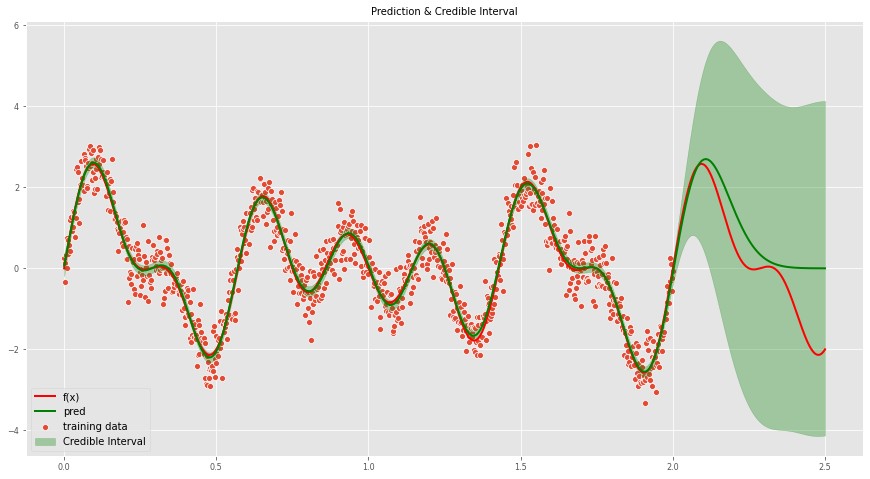

In [606]:
fig, ax = plt.subplots(figsize=(15, 8))

# Plot training data.
sns.scatterplot(x=x, y=y, label='training data', ax=ax);

# Plot "true" linear fit.
sns.lineplot(
    x=x_star, 
    y=f(x_star), 
    color='red', 
    label='f(x)', 
    ax=ax
)

# Plot corridor. 
ax.fill_between(
    x=x_star, 
    y1=(y_hat - 2*y_hat_sd), 
    y2=(y_hat + 2*y_hat_sd), 
    color='green',
    alpha=0.3, 
    label='Credible Interval'
)

# Plot prediction. 
sns.lineplot(x=x_star, y=y_pred, color='green', label='pred')
ax.set(title='Prediction & Credible Interval')
ax.legend(loc='lower left');